# AAIB - Capsule endoscopy triage demo

This notebook is a **runnable, traceable demo** of the binary triage pipeline
described in the report: classifying capsule-endoscopy frames as
**normal vs abnormal**, building on the Kvasir-Capsule subclass labels.

It is meant to run end-to-end on a local clone or a Colab runtime (where you upload the required repository files and run artifacts):

1. Load a small **sample of the labelled data** (`data/demo_sample/`) and
   reproduce the **same preprocessing and stratified-split logic** used for
   the reported run.
2. Build the **same `MobileNetV3-Large` model**, loss, optimizer, and
   augmentation pipeline as the real training script.
3. **Load the saved checkpoint** from the reported run and run
   **one additional live epoch** on the demo sample - enough to demonstrate
   the actual training/evaluation code path without needing hours of compute.
4. Display the **saved training curves, calibrated threshold, and test-set
   metrics from the real run**, so the reported numbers are shown
   side-by-side with what this demo can reproduce on a laptop.

For Colab, upload the repository files, saved run directory, and test results listed in
section 10. The notebook keeps running without the run artifacts, but they are
what make the reported curves, calibration, and test metrics appear.

See section 10 for exactly how the pieces here map back to the report, and
what is illustrative-of-the-pipeline versus a reproduction-of-the-result.

## 1. Setup

Locally this just locates the repo root, but on Colab you will need to manually upload the necessary files. Either way, `PROJECT_ROOT` ends up
pointing at a directory that has `src/kvasir_triage`, `data/demo_sample/`, and
`outputs/` available.

If you are running this from a bare Colab session, upload the following
files to the Colab environment:

**Repository files:**
- `requirements.txt`
- `src/kvasir_triage/` (and all its contents)
- `data/demo_sample/` (and all its contents)
- `outputs/preprocessed/normalization_stats.json`
- `outputs/test_evaluation/mobilenet_v3_large_test_results.json`

**Run artifacts (for replicating the reported numbers):**
- `outputs/runs/mobilenet_v3_large_full_fold0/checkpoints/best.pt`
- `outputs/runs/mobilenet_v3_large_full_fold0/metrics.jsonl`
- `outputs/runs/mobilenet_v3_large_full_fold0/config.snapshot.yaml`
- `outputs/runs/mobilenet_v3_large_full_fold0/val_preds_best.npz` or `eval_predictions_val.npz`
- `outputs/runs/mobilenet_v3_large_full_fold0/threshold_calibration.json`

In [ ]:
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.amp import autocast
from torch.utils.data import DataLoader, Dataset

IN_COLAB = "google.colab" in sys.modules or bool(os.environ.get("COLAB_RELEASE_TAG"))

def find_project_root() -> Path:
    here = Path.cwd()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "kvasir_triage").is_dir():
            return candidate
    if IN_COLAB:
        return Path("/content")
    return here

PROJECT_ROOT = find_project_root()

if not (PROJECT_ROOT / "src" / "kvasir_triage").is_dir():
    raise RuntimeError(
        f"Could not find src/kvasir_triage/ in {PROJECT_ROOT}. "
        "Please upload the necessary repository files to Colab before running this notebook."
    )

if IN_COLAB and (PROJECT_ROOT / "requirements.txt").exists():
    os.system(f"pip install -q -r {PROJECT_ROOT}/requirements.txt")

sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.chdir(PROJECT_ROOT)
print("PROJECT_ROOT =", PROJECT_ROOT)

from kvasir_triage.data.labels import BINARY_LABEL, DIR_NAME_MAP, is_excluded
from kvasir_triage.data.preprocess import preprocess_image_to_uint8
from kvasir_triage.data.splits import build_subclass_stratified_splits, infer_video_id
from kvasir_triage.data.transforms import AlbumentationsWrapper, build_eval_transform, build_train_transform
from kvasir_triage.eval.metrics import compute_metrics, per_subclass_recall
from kvasir_triage.eval.threshold import find_threshold_by_recall
from kvasir_triage.losses.focal import BinaryFocalLoss
from kvasir_triage.models.registry import build_model
from kvasir_triage.training.checkpoint import load_checkpoint
from kvasir_triage.utils import load_json, save_json

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 10,
})
print("device =", DEVICE)

PROJECT_ROOT = d:\Git\AAIB
device = cpu


## 2. The demo data sample

`data/demo_sample/` ships with the repo (it is the one exception to the
`data/*` gitignore rule). It was produced by
[`scripts/build_demo_sample.py`](../scripts/build_demo_sample.py), which:

- scans `data/labelled_images/` the same way `scripts/preprocess.py` does
  (mapping raw directory names through `DIR_NAME_MAP` and dropping
  `is_excluded` subclasses),
- for every subclass, picks frames from up to 6 source videos (the
  best-represented ones), spreading the picked frames across each video's
  frame range,
- copies ~485 frames total into `data/demo_sample/labelled_images/`
  (mirroring the original directory layout) plus a filtered
  `metadata_sample.csv`.

Picking frames from multiple videos per subclass matters: the real splitter
assigns whole `(video_id, subclass)` groups to a single split, so a
single-video subclass could never appear in train, val, *and* test at once.

In [16]:
DEMO_DIR = PROJECT_ROOT / "data" / "demo_sample"
DEMO_IMAGES_DIR = DEMO_DIR / "labelled_images"

rows = []
for class_dir in sorted(DEMO_IMAGES_DIR.iterdir()):
    if not class_dir.is_dir():
        continue
    subclass = DIR_NAME_MAP.get(class_dir.name, class_dir.name)
    if is_excluded(subclass):
        continue
    for path in sorted(class_dir.rglob("*.jpg")):
        stem = path.stem
        rows.append({
            "path": path,
            "stem": stem,
            "subclass": subclass,
            "video_id": infer_video_id(stem),
            "binary_label": BINARY_LABEL[subclass],
        })

image_df = pd.DataFrame(rows)
print(f"{len(image_df)} frames, {image_df['subclass'].nunique()} subclasses, "
      f"{image_df['video_id'].nunique()} source videos")
image_df.groupby("subclass").agg(
    frames=("stem", "size"),
    videos=("video_id", "nunique"),
    binary_label=("binary_label", "first"),
)

485 frames, 10 subclasses, 28 source videos


,frames,videos,binary_label
subclass,,,
Angiectasia,60,6,1
Erosion,60,6,1
Erythema,29,3,1
Foreign body,36,4,1
Ileocecal valve,60,6,0
Lymphangiectasia,30,3,1
Normal clean mucosa,60,6,0
Pylorus,60,6,0
Reduced mucosal view,60,6,0


## 3. Stratified train/val/test splits

`build_subclass_stratified_splits` (the function the real pipeline uses, see
[`src/kvasir_triage/data/splits.py`](../src/kvasir_triage/data/splits.py))
assigns whole `(video_id, subclass)` groups to a single split - this keeps all
frames from one video and one subclass together, which avoids
within-class-within-video leakage between train and val/test. Frames from the
same video but a *different* subclass can still land in a different split.

We call it with the exact same arguments as `scripts/preprocess.py`, just on
our much smaller `image_df`.

In [17]:
SEED = 42

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    manifest = build_subclass_stratified_splits(image_df, seed=SEED)

print(manifest.groupby(["split", "binary_label"]).size().unstack(fill_value=0))
print()
print(manifest["split"].value_counts())

binary_label    0    1
split                 
test           40   60
train         160  129
val            40   56

split
train    289
test     100
val       96
Name: count, dtype: int64


## 4. Preprocessing

`preprocess_image_to_uint8` (used by `scripts/preprocess.py` to build the
training shards) crops the circular endoscope field of view, masks out the
black border, and resizes to a fixed square - the same transform every frame
goes through before it ever reaches a model. We run it here on a few sample
frames just to show what the network actually sees.

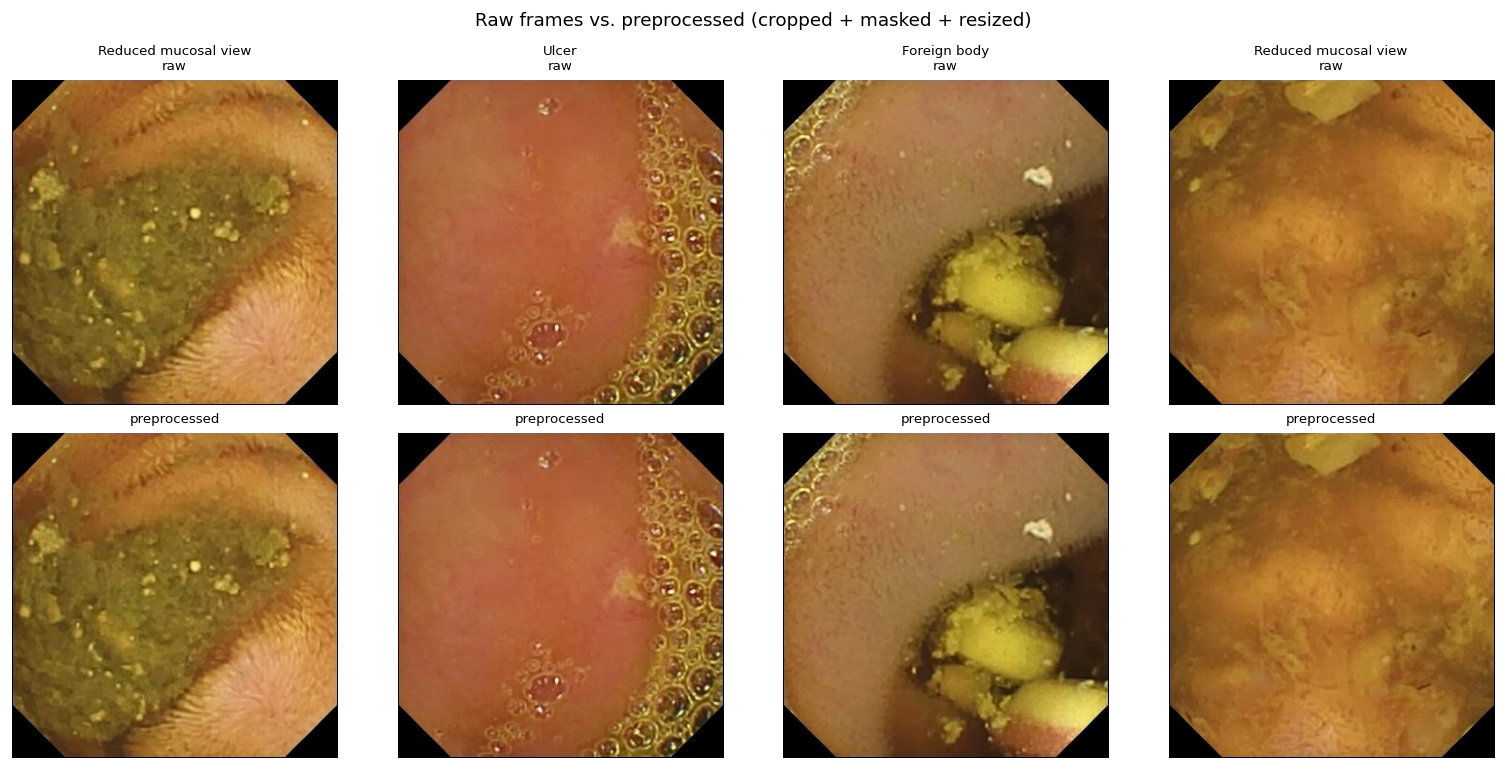

In [18]:
sample_rows = manifest.sample(n=4, random_state=SEED)

fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for col, row in enumerate(sample_rows.itertuples()):
    raw = plt.imread(row.path)
    processed = preprocess_image_to_uint8(row.path)
    axes[0, col].imshow(raw)
    axes[0, col].set_title(f"{row.subclass}\nraw", fontsize=8)
    axes[1, col].imshow(processed)
    axes[1, col].set_title("preprocessed", fontsize=8)
    for ax in (axes[0, col], axes[1, col]):
        ax.axis("off")
fig.suptitle("Raw frames vs. preprocessed (cropped + masked + resized)", fontsize=11)
fig.tight_layout()
plt.show()

## 5. Augmentation and datasets

`build_train_transform` / `build_eval_transform` build the same
torchvision-style augmentation pipelines used for training and evaluation
(random flips/affine jitter for train, deterministic normalize for eval),
parameterized by the dataset's saved normalization statistics
(`outputs/preprocessed/normalization_stats.json`, which ships with the repo).

This notebook uses a small notebook-local dataset wrapper that loads the demo
sample frames on the fly, preprocesses them with the repo's
`preprocess_image_to_uint8`, and then feeds them through the shared transform
builders. That keeps the demo small while still exercising the same code path
as the real pipeline.

In [19]:
norm_stats = load_json(PROJECT_ROOT / "outputs" / "preprocessed" / "normalization_stats.json")
train_stats = norm_stats.get("train", norm_stats.get("fold_0"))
if train_stats is None:
    raise KeyError("normalization_stats.json must contain 'train' or legacy 'fold_0' stats.")
mean, std = train_stats["mean"], train_stats["std"]
print("normalization stats:", train_stats)

train_tf = AlbumentationsWrapper(build_train_transform(mean, std))
eval_tf = AlbumentationsWrapper(build_eval_transform(mean, std))


class DemoFrameDataset(Dataset):
    def __init__(self, frame_df: pd.DataFrame, transform=None):
        self.frame_df = frame_df.reset_index(drop=True)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.frame_df)

    def __getitem__(self, idx: int):
        row = self.frame_df.iloc[idx]
        image = preprocess_image_to_uint8(row.path)
        if self.transform is not None:
            image = self.transform(image)
        label = int(row.binary_label)
        meta = {
            "subclass": row.subclass,
            "path": str(row.path),
            "stem": row.stem,
            "video_id": row.video_id,
        }
        return image, label, meta


train_df = manifest[manifest["split"] == "train"].reset_index(drop=True)
val_df = manifest[manifest["split"] == "val"].reset_index(drop=True)
test_df = manifest[manifest["split"] == "test"].reset_index(drop=True)

train_ds = DemoFrameDataset(train_df, transform=train_tf)
val_ds = DemoFrameDataset(val_df, transform=eval_tf)
test_ds = DemoFrameDataset(test_df, transform=eval_tf)

print(f"train={len(train_ds)}  val={len(val_ds)}  test={len(test_ds)}")

BATCH_SIZE = 16
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

images, labels, metas = next(iter(train_loader))
print("batch:", images.shape, labels.shape, images.dtype, labels.dtype)

normalization stats: {'mean': [0.6029480562192047, 0.369929941537287, 0.18638786076187555], 'std': [0.1813843834104082, 0.13227436299372275, 0.09027251296739751], 'n_pixels': 3708623360}
train=289  val=96  test=100
batch: torch.Size([16, 3, 336, 336]) torch.Size([16]) torch.float32 torch.int64


### A look at the augmented training batch

Unnormalizing a few training-loader samples shows the random flips, rotation,
and color jitter `build_train_transform` applies - the same augmentation the
real run trained under.

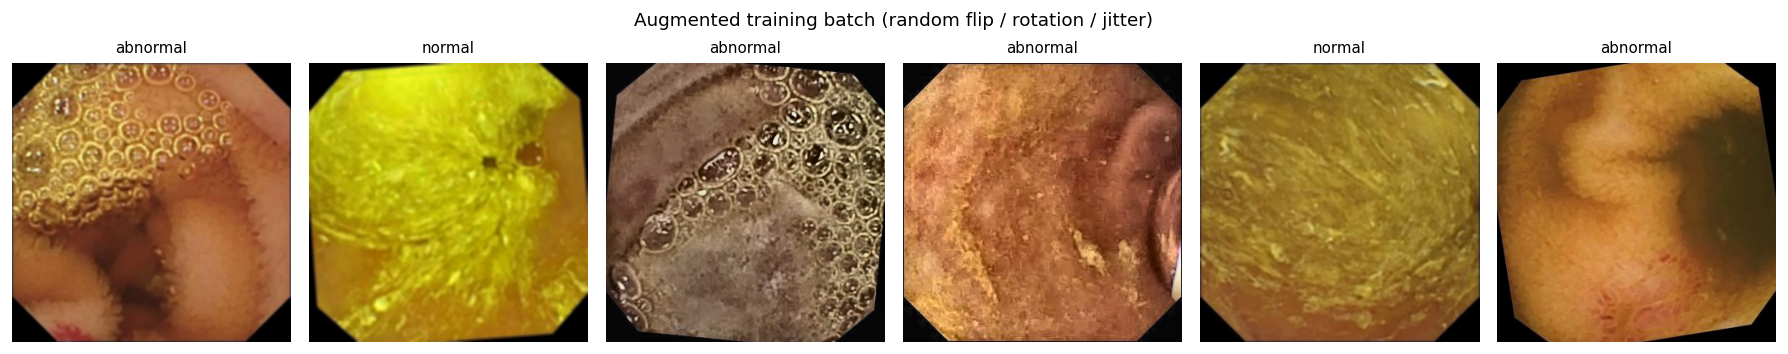

In [20]:
mean_t = torch.tensor(mean).view(3, 1, 1)
std_t = torch.tensor(std).view(3, 1, 1)


def unnormalize(img: torch.Tensor) -> np.ndarray:
    arr = (img * std_t + mean_t).clamp(0, 1)
    return arr.permute(1, 2, 0).numpy()


fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax, img, label in zip(axes, images, labels):
    ax.imshow(unnormalize(img))
    ax.set_title("abnormal" if label.item() else "normal", fontsize=9)
    ax.axis("off")
fig.suptitle("Augmented training batch (random flip / rotation / jitter)", fontsize=11)
fig.tight_layout()
plt.show()

## 6. Model, loss, optimizer

`build_model("mobilenet_v3_large", ...)` constructs the same torchvision
backbone with a binary classification head that `scripts/train.py` builds for
this architecture. The reported run used `BinaryFocalLoss` (focal loss with a
configurable `alpha`/`gamma`, useful for the class imbalance between normal
and abnormal frames) and an `AdamW` optimizer with a cosine LR schedule.

In [21]:
MODEL_NAME = "mobilenet_v3_large"
DISPLAY_NAME = "MobileNet-V3-Large"

model = build_model(MODEL_NAME, {"pretrained": False, "dropout": 0.2}).to(DEVICE)

criterion = BinaryFocalLoss(alpha=0.25, gamma=2.0)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=1)

n_params = sum(p.numel() for p in model.parameters())
print(f"{DISPLAY_NAME}: {n_params:,} parameters")

MobileNet-V3-Large: 4,203,313 parameters


## 7. Loading the reported checkpoint

The reported numbers come from a run saved under
`outputs/runs/mobilenet_v3_large_full_fold0/`. That directory is gitignored
(checkpoints are large), so it is only present on a machine that already has
the full `outputs/` tree - e.g. the original training machine, or a Colab
session where you have uploaded the run artifacts listed in section 1.

If it is not found, we fall back to the `pretrained=False` (random-init) model
built above - the rest of the notebook still runs, it just starts the live
epoch from scratch instead of from the converged weights.

In [22]:
RUN_DIR = PROJECT_ROOT / "outputs" / "runs" / f"{MODEL_NAME}_full_fold0"
CHECKPOINT_PATH = RUN_DIR / "checkpoints" / "best.pt"

loaded_from_checkpoint = False
if CHECKPOINT_PATH.exists():
    state = load_checkpoint(CHECKPOINT_PATH, map_location=DEVICE)
    state_dict = state.get("model", state.get("model_state_dict", state))
    model.load_state_dict(state_dict)
    loaded_from_checkpoint = True
    print(f"Loaded checkpoint from {CHECKPOINT_PATH}")
else:
    print(
        f"No checkpoint found at {CHECKPOINT_PATH} - "
        "outputs/runs/ is gitignored and not present in this checkout.\n"
        "Continuing with the randomly-initialized model from section 6; "
        "the live epoch below still exercises the same code path, just "
        "without the converged starting weights."
    )

Loaded checkpoint from d:\Git\AAIB\outputs\runs\mobilenet_v3_large_full_fold0\checkpoints\best.pt


## 8. One live epoch

This is the actual training/evaluation loop from `scripts/train.py`,
condensed to a single epoch over the demo sample - just enough to demonstrate
the real code path (forward pass, focal loss, backward pass, optimizer step,
metric computation) on hardware that does not have hours to spare.

A note on `BinaryFocalLoss`: it expects the **raw** `[B, 1]` logits and does
the squeeze internally, so we pass `raw_logits` straight to `criterion` and
only flatten a detached copy afterwards for `compute_metrics`.

In [23]:
def run_epoch(loader, train: bool):
    model.train(train)
    total_loss = 0.0
    n_batches = 0
    all_logits, all_labels = [], []

    context = torch.enable_grad() if train else torch.no_grad()
    with context:
        for images, labels, _meta in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE).float()

            with autocast(device_type=DEVICE.type, enabled=DEVICE.type == "cuda"):
                raw_logits = model(images)
                loss = criterion(raw_logits, labels)

            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item()
            n_batches += 1
            all_logits.append(raw_logits.squeeze(1).detach().cpu())
            all_labels.append(labels.detach().cpu())

    logits = torch.cat(all_logits).numpy()
    targets = torch.cat(all_labels).numpy()
    metrics = compute_metrics(logits, targets)
    metrics["loss"] = total_loss / max(n_batches, 1)
    return metrics


print("Before the live epoch (using the loaded weights as-is):")
before_metrics = run_epoch(val_loader, train=False)
print({k: round(v, 4) for k, v in before_metrics.items()})

print("\nRunning one live training epoch over the demo train split ...")
train_metrics = run_epoch(train_loader, train=True)
scheduler.step()
print({k: round(v, 4) for k, v in train_metrics.items()})

print("\nAfter the live epoch:")
after_metrics = run_epoch(val_loader, train=False)
print({k: round(v, 4) for k, v in after_metrics.items()})

pd.DataFrame(
    [before_metrics, train_metrics, after_metrics],
    index=["val (before)", "train (live epoch)", "val (after)"],
).round(4)

Before the live epoch (using the loaded weights as-is):
{'pr_auc': 0.9534, 'mcc': 0.6402, 'npv': 0.6557, 'tp': 35, 'fp': 0, 'tn': 40, 'fn': 21, 'loss': 0.1028}

Running one live training epoch over the demo train split ...
{'pr_auc': 0.9199, 'mcc': 0.6834, 'npv': 0.8065, 'tp': 93, 'fp': 10, 'tn': 150, 'fn': 36, 'loss': 0.0509}

After the live epoch:
{'pr_auc': 0.9532, 'mcc': 0.6714, 'npv': 0.6964, 'tp': 39, 'fp': 1, 'tn': 39, 'fn': 17, 'loss': 0.078}


,pr_auc,mcc,npv,tp,fp,tn,fn,loss
val (before),0.9534,0.6402,0.6557,35,0,40,21,0.1028
train (live epoch),0.9199,0.6834,0.8065,93,10,150,36,0.0509
val (after),0.9532,0.6714,0.6964,39,1,39,17,0.0780


## 9. The actual reported results

Everything above ran live, on the small demo sample, in a few minutes. The
numbers below are different: they are the **saved artifacts from the real
Mobilenet run** referenced in the report, loaded directly from
`outputs/runs/mobilenet_v3_large_full_fold0/metrics.jsonl` (training curves),
`outputs/runs/mobilenet_v3_large_full_fold0/threshold_calibration.json`
(validation-calibrated threshold), and
`outputs/test_evaluation/mobilenet_v3_large_test_results.json`
(held-out test metrics, which ships with the repo and is always available).

If `metrics.jsonl` is not present (gitignored, same as the checkpoint), the
curve plot is skipped and only the test results - which *do* ship with the
repo - are shown.

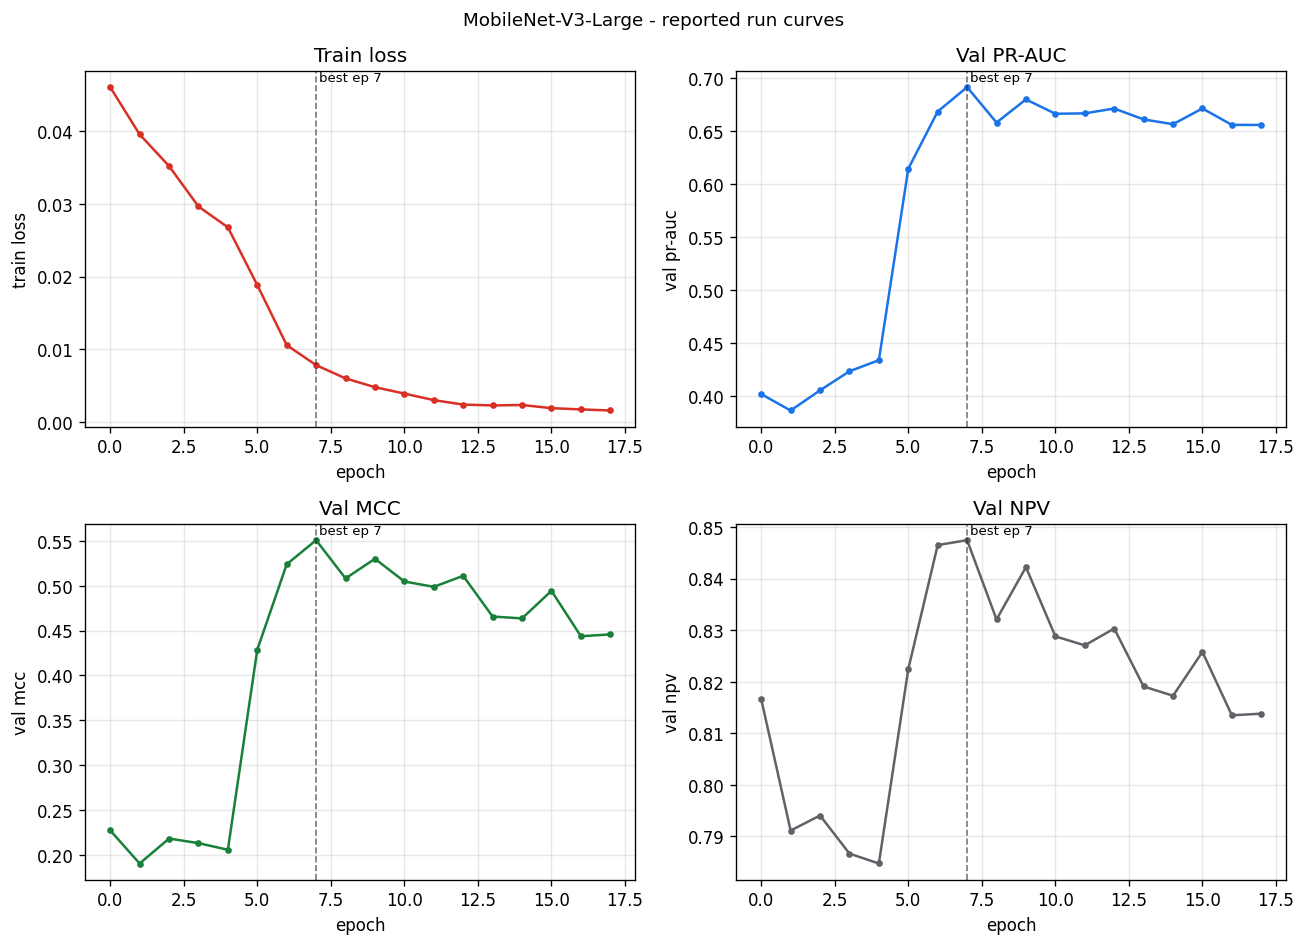

 epoch  train_loss  val_pr_auc  val_mcc  val_npv
    13    0.002263    0.660789 0.465756 0.819089
    14    0.002322    0.656271 0.463646 0.817289
    15    0.001887    0.671101 0.494402 0.825797
    16    0.001717    0.655638 0.443780 0.813499
    17    0.001564    0.655570 0.445808 0.813812


In [24]:
def load_metrics(run_dir) -> pd.DataFrame:
    if run_dir is None:
        return pd.DataFrame()
    path = run_dir / "metrics.jsonl"
    if not path.exists():
        return pd.DataFrame()
    records = [json.loads(line) for line in path.read_text().splitlines() if line.strip()]
    return pd.DataFrame(records)


metrics_df = load_metrics(RUN_DIR if RUN_DIR.exists() else None)

if metrics_df.empty:
    print(
        f"{RUN_DIR / 'metrics.jsonl'} not found - outputs/runs/ is gitignored.\n"
        "Skipping the live curve plot; the test-set results below still load "
        "from the tracked outputs/test_evaluation/ directory."
    )
else:
    plot_specs = [
        ("train_loss", "Train loss", "#d93025"),
        ("val_pr_auc", "Val PR-AUC", "#1a73e8"),
        ("val_mcc", "Val MCC", "#188038"),
        ("val_npv", "Val NPV", "#5f6368"),
    ]
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    axes_flat = axes.ravel()
    best_epoch = int(metrics_df.loc[metrics_df["val_pr_auc"].idxmax(), "epoch"]) if "val_pr_auc" in metrics_df.columns else None
    for ax, (col, title, color) in zip(axes_flat, plot_specs):
        if col not in metrics_df.columns:
            ax.set_visible(False)
            continue
        ax.plot(metrics_df["epoch"], metrics_df[col], marker="o", markersize=3, color=color)
        if best_epoch is not None:
            ax.axvline(best_epoch, color="#202124", linestyle="--", linewidth=1, alpha=0.6)
            ax.text(best_epoch + 0.1, ax.get_ylim()[1], f"best ep {best_epoch}", fontsize=8, va="top")
        ax.set(title=title, xlabel="epoch", ylabel=title.lower())
        ax.grid(True, alpha=0.3)
    fig.suptitle(f"{DISPLAY_NAME} - reported run curves", fontsize=11)
    fig.tight_layout()
    plt.show()

    display_columns = [c for c in ["epoch", "train_loss", "val_pr_auc", "val_mcc", "val_npv"] if c in metrics_df.columns]
    print(metrics_df[display_columns].tail(5).to_string(index=False))

### Held-out test set metrics

`outputs/test_evaluation/mobilenet_v3_large_test_results.json` is the exact
file the report's test-set table draws from. It includes the overall binary
metrics, the calibrated decision threshold, the confusion matrix counts, and
per-subclass recall (how well the model catches each abnormal finding type,
not just "abnormal" as a whole).

In [25]:
def load_validation_predictions(run_dir: Path):
    for name in ("eval_predictions_val.npz", "val_preds_best.npz"):
        path = run_dir / name
        if not path.exists():
            continue
        data = np.load(path, allow_pickle=True)
        logits = data["logits"]
        labels = data["true_labels"] if "true_labels" in data.files else data["labels"]
        subclasses = data["subclasses"].astype(str)
        if logits.ndim == 2 and logits.shape[1] == 1:
            logits = logits[:, 0]
        return path, logits, labels, subclasses
    return None


def load_or_calibrate_threshold(run_dir: Path):
    cal_path = run_dir / "threshold_calibration.json"
    if cal_path.exists():
        return cal_path, load_json(cal_path)

    loaded = load_validation_predictions(run_dir)
    if loaded is None:
        return None, None

    source_path, logits, labels, subclasses = loaded
    threshold = find_threshold_by_recall(logits, labels)
    if threshold.get("threshold") is not None:
        threshold["subclass_recall"] = per_subclass_recall(
            logits, labels, subclasses, threshold=threshold["threshold"]
        )
    threshold["source"] = str(source_path)
    return source_path, threshold


cal_source, threshold_calibration = load_or_calibrate_threshold(RUN_DIR)
if threshold_calibration is None:
    print(f"No calibration file or validation predictions found in {RUN_DIR}.")
else:
    print(f"Loaded calibration from {cal_source}")
    display(pd.Series({k: v for k, v in threshold_calibration.items() if not isinstance(v, dict)}, name="value").to_frame().round(4))

TEST_RESULTS_PATH = PROJECT_ROOT / "outputs" / "test_evaluation" / f"{MODEL_NAME}_test_results.json"
test_results = load_json(TEST_RESULTS_PATH)

test_default = test_results.get("metrics_at_0.5", {})
test_calibrated = test_results.get("metrics_at_calibrated_threshold", {})

summary_rows = []
if threshold_calibration is not None:
    summary_rows.append({
        "source": "val calibration",
        "threshold": threshold_calibration.get("threshold"),
        "recall": threshold_calibration.get("recall"),
        "precision": threshold_calibration.get("precision"),
        "status": threshold_calibration.get("status"),
    })
if test_default:
    summary_rows.append({
        "source": "test @ 0.5",
        "pr_auc": test_default.get("pr_auc"),
        "mcc": test_default.get("mcc"),
        "npv": test_default.get("npv"),
    })
if test_calibrated:
    summary_rows.append({
        "source": f"test @ t={test_calibrated.get('threshold', float('nan')):.3f}",
        "precision": test_calibrated.get("precision"),
        "recall": test_calibrated.get("recall"),
        "npv": test_calibrated.get("npv"),
    })

print(f"Loaded {TEST_RESULTS_PATH.name}")
display(pd.DataFrame(summary_rows).round(4))

Loaded calibration from d:\Git\AAIB\outputs\runs\mobilenet_v3_large_full_fold0\threshold_calibration.json


,value
pr_auc,0.691161
mcc,0.550897
npv,0.84746
tp,882
fp,99
tn,6739
fn,1213
threshold,0.047057
recall,0.900716
precision,0.263511


Loaded mobilenet_v3_large_test_results.json


,source,threshold,recall,precision,status,pr_auc,mcc,npv
0,val calibration,0.0471,0.9007,0.2635,ok,NaN,NaN,NaN
1,test @ 0.5,NaN,NaN,NaN,NaN,0.5542,0.4918,0.9163
2,test @ t=0.047,NaN,0.9496,0.1653,NaN,NaN,NaN,0.9651


### Confusion matrix and the BCE -> Focal threshold story

The report describes how the team moved from a plain BCE loss to a
recall-anchored focal-loss + calibrated-threshold setup, specifically to push
recall on abnormal frames up (missing an abnormal frame is the costly error in
a triage setting). The saved test-results JSON carries both the confusion
matrix at the calibrated threshold and the threshold value itself, which we
plot here next to a default 0.5 cutoff for context.

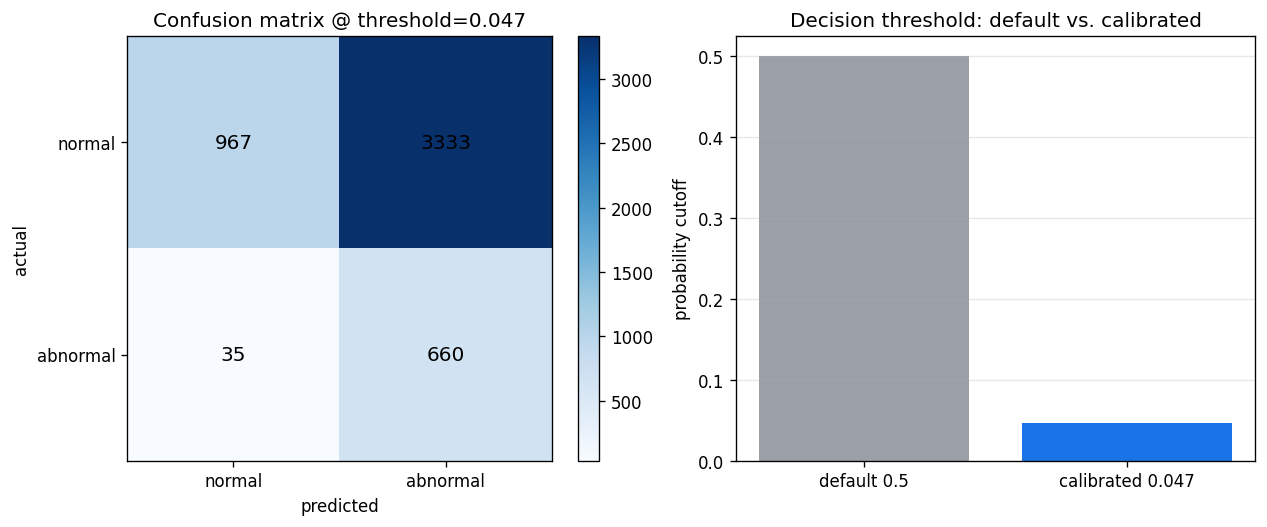

In [26]:
cm_source = test_calibrated if test_calibrated else test_default
if not cm_source:
    print("No test metrics available for the confusion-matrix plot.")
else:
    threshold = test_calibrated.get("threshold", threshold_calibration.get("threshold", 0.5) if threshold_calibration else 0.5)
    tn = int(cm_source.get("tn", 0))
    fp = int(cm_source.get("fp", 0))
    fn = int(cm_source.get("fn", 0))
    tp = int(cm_source.get("tp", 0))
    cm = np.array([[tn, fp], [fn, tp]])

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    im = axes[0].imshow(cm, cmap="Blues")
    axes[0].set(
        title=f"Confusion matrix @ threshold={threshold:.3f}",
        xticks=[0, 1], yticks=[0, 1],
        xticklabels=["normal", "abnormal"], yticklabels=["normal", "abnormal"],
        xlabel="predicted", ylabel="actual",
    )
    for i in range(2):
        for j in range(2):
            axes[0].text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=12)
    fig.colorbar(im, ax=axes[0], fraction=0.046)

    axes[1].bar(["default 0.5", f"calibrated {threshold:.3f}"], [0.5, threshold], color=["#9aa0a6", "#1a73e8"])
    axes[1].set(
        title="Decision threshold: default vs. calibrated",
        ylabel="probability cutoff",
    )
    axes[1].grid(True, alpha=0.3, axis="y")

    fig.tight_layout()
    plt.show()

### Per-subclass recall on the test set

`subclass_recall_at_calibrated_threshold` in the saved results breaks the
abnormal-class recall down by finding type - this is the figure the report uses
to argue the model is not just good at the easy/common conditions. For
context, the notebook also shows the pre-calibration recall where that file
contains it.

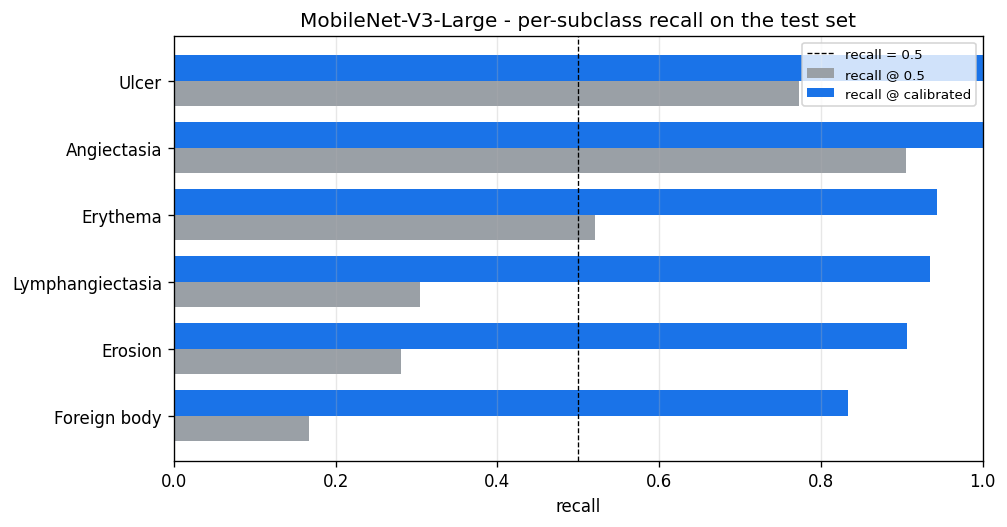

In [27]:
baseline_recall = pd.Series(test_results.get("subclass_recall", {}), name="recall @ 0.5")
calibrated_recall = pd.Series(test_results.get("subclass_recall_at_calibrated_threshold", {}), name="recall @ calibrated")

recall_df = pd.concat([baseline_recall, calibrated_recall], axis=1).sort_index()
if recall_df.dropna(how="all").empty:
    print("No subclass recall data available.")
else:
    recall_df = recall_df.sort_values(by=recall_df.columns[-1], ascending=True, na_position="last")
    fig, ax = plt.subplots(figsize=(8.5, 0.45 * len(recall_df) + 1.8))
    y = np.arange(len(recall_df))
    width = 0.38

    if recall_df.iloc[:, 0].notna().any():
        ax.barh(y - width / 2, recall_df.iloc[:, 0].fillna(0.0), height=width, color="#9aa0a6", label=recall_df.columns[0])
    ax.barh(y + width / 2, recall_df.iloc[:, -1].fillna(0.0), height=width, color="#1a73e8", label=recall_df.columns[-1])

    ax.set_yticks(y)
    ax.set_yticklabels(recall_df.index)
    ax.set(xlim=(0, 1), xlabel="recall", title=f"{DISPLAY_NAME} - per-subclass recall on the test set")
    ax.axvline(0.5, color="black", linewidth=0.8, linestyle="--", label="recall = 0.5")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, axis="x")
    fig.tight_layout()
    plt.show()

## 10. Limitations and how this maps to the report

- **Sample size.** `data/demo_sample/` has about 485 frames from a handful of
  source videos per subclass, against the full `data/labelled_images/` set
  used for the reported run. Splits, class balance, and the live-epoch metrics
  above are all proportionally smaller and noisier than the real thing - they
  are illustrative of the *pipeline*, not a reproduction of the *result*.
- **One epoch, not a full training run.** The reported numbers come from a
  longer GPU training run under `outputs/runs/mobilenet_v3_large_full_fold0/`.
  Running that here would take too long on a CPU runtime, so this notebook
  loads the checkpoint and runs one additional live epoch to demonstrate the
  same code path, then separately displays the saved curves, threshold
  calibration, and test metrics from the real run (section 9).
- **Gitignored run artifacts.** `outputs/runs/` is gitignored because of size;
  only the tracked `outputs/test_evaluation/*_test_results.json` files and
  `outputs/preprocessed/normalization_stats.json` ship with the repo. On a
  machine that has the full `outputs/runs/` tree (e.g. the original training
  machine), sections 7 to 9 above pick those files up automatically and the
  comparisons become directly traceable end-to-end.
- **Colab upload list.** If you are starting from a fresh Colab session, upload
  the following files:
  - `requirements.txt`
  - `src/kvasir_triage/` (and all its contents)
  - `data/demo_sample/` (and all its contents)
  - `outputs/preprocessed/normalization_stats.json`
  - `outputs/test_evaluation/mobilenet_v3_large_test_results.json`
  - `outputs/runs/mobilenet_v3_large_full_fold0/checkpoints/best.pt`
  - `outputs/runs/mobilenet_v3_large_full_fold0/metrics.jsonl`
  - `outputs/runs/mobilenet_v3_large_full_fold0/config.snapshot.yaml`
  - `outputs/runs/mobilenet_v3_large_full_fold0/val_preds_best.npz` or
    `eval_predictions_val.npz`
  - `outputs/runs/mobilenet_v3_large_full_fold0/threshold_calibration.json`

For the full picture - all models, all folds, cross-validation summaries, and
the report-quality figures - see `notebooks/results_comparison.ipynb` and the
per-model `notebooks/results_<model>.ipynb` notebooks, which read from the
complete (non-demo) `outputs/` tree.